In [4]:
# Load feature importance datasets

import pandas as pd

## validation importance data
df_A = pd.read_csv(
    r"/Users/nigus/Library/CloudStorage/OneDrive-MonashUniversity/PhD/CSAI validation/Codes/feature_importance_original.csv")

In [5]:
## Extended importance data

df_B = pd.read_csv(
    r"/Users/nigus/Library/CloudStorage/OneDrive-MonashUniversity/PhD/CSAI validation/Codes/feature_importance_extended.csv")

In [6]:
feature_imp_pairs_original = list(zip(df_A.Feature, df_A.Importance))
feature_imp_pairs_extended = list(zip(df_B.Feature, df_B.Importance))

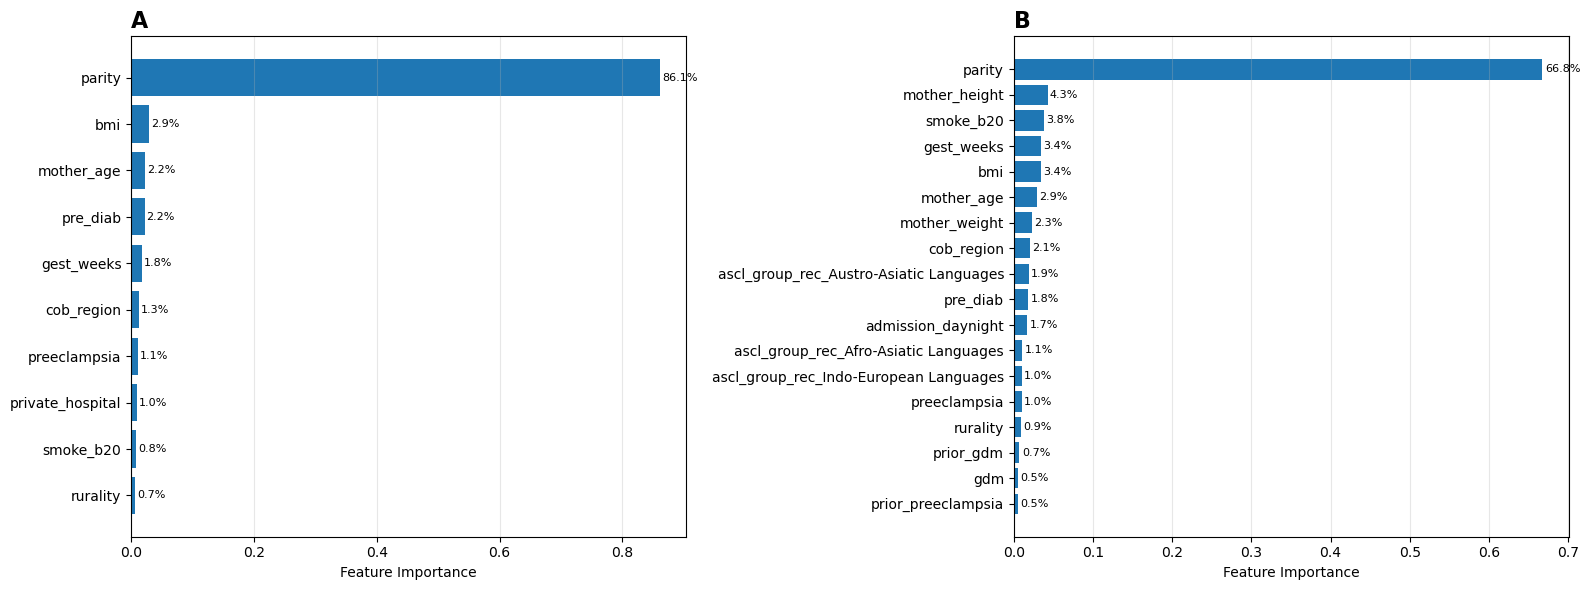

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Prepare data

# Sort by importance (descending)
feature_imp_pairs_original.sort(key=lambda x: x[1], reverse=True)
feature_imp_pairs_extended.sort(key=lambda x: x[1], reverse=True)

# Original model (all features)
features_A = [x[0] for x in feature_imp_pairs_original]
importances_A = [x[1] for x in feature_imp_pairs_original]
total_A = np.sum(importances_A)

# Extended model (Top 15 features)
top_n = 18
features_B = [x[0] for x in feature_imp_pairs_extended[:top_n]]
importances_B = [x[1] for x in feature_imp_pairs_extended[:top_n]]
total_B = np.sum([x[1] for x in feature_imp_pairs_extended])


# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A 
axes[0].barh(features_A, importances_A)
axes[0].invert_yaxis()
axes[0].set_xlabel("Feature Importance")
axes[0].set_title("A", loc="left", fontsize=16, fontweight="bold")

for i, imp in enumerate(importances_A):
    axes[0].text(
        imp + 0.003,
        i,
        f"{imp/total_A*100:.1f}%",
        va="center",
        fontsize=8
    )

axes[0].grid(axis="x", alpha=0.3)

#  Panel B 
axes[1].barh(features_B, importances_B)
axes[1].invert_yaxis()
axes[1].set_xlabel("Feature Importance")
axes[1].set_title("B", loc="left", fontsize=16, fontweight="bold")

for i, imp in enumerate(importances_B):
    axes[1].text(
        imp + 0.003,
        i,
        f"{imp/total_B*100:.1f}%",
        va="center",
        fontsize=8
    )

axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()

# Save figure
plt.savefig('Feature_Importance_Comparison.tiff', 
           format='tiff', 
           dpi=300, 
           bbox_inches='tight',
           facecolor='white',
           edgecolor='none')